# Termômetro da Sala — previsão do índice de calor

**Global Solution 2026.2 (CitizenTech) — IA e Machine Learning**

| Campo | Conteúdo |
|---|---|
| Problema | Nas tardes quentes, a sala de aula passa do limite seguro sem que ninguém meça, e a escola só reage quando alguém passa mal |
| Cidadão beneficiado | Professor(a) e turma de uma sala sem climatização; quem opera é a coordenação |
| O que o modelo faz | Prevê o **índice de calor da rua daqui a 2 horas**. A API soma a diferença medida entre a sala e a rua (o *delta* da sala, vindo do sensor ESP32) e mostra o nível previsto da sala no app e no desktop |
| Dados | Reais e públicos: INMET, estação automática A701 (São Paulo, Mirante de Santana), dados horários de 2022 a 2025 |
| Métricas | MAE do índice (°C) e F1 macro dos níveis, comparados com o baseline "daqui a 2 h = agora" |

Integrantes: Samuel Baecker — RM [preencher]

## 1. Dados
O arquivo `dados/inmet_a701.csv` foi extraído dos zips anuais do INMET por `extrair_a701.py`. O INMET registra a hora em **UTC**; São Paulo é UTC−3 (sem horário de verão desde 2019).

In [1]:
import json, math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error, f1_score

df = pd.read_csv('dados/inmet_a701.csv', parse_dates=['data_hora_utc'])
df['data_hora_utc'] = pd.to_datetime(df['data_hora_utc'], utc=True)
df = df.drop_duplicates('data_hora_utc').set_index('data_hora_utc').sort_index()
df['local'] = df.index.tz_convert('America/Sao_Paulo')
# vetor de teste do relógio (CONTRATO.md): 15/01/2026 às 1700 UTC = 14h em São Paulo
assert pd.Timestamp('2026-01-15 17:00', tz='UTC').tz_convert('America/Sao_Paulo').hour == 14
print(len(df), 'horas válidas de', df.index.min().date(), 'a', df.index.max().date())
df.describe()[['temperatura_c', 'umidade_pct']]

34786 horas válidas de 2022-01-01 a 2025-12-31


,temperatura_c,umidade_pct
count,34786.000000,34786.000000
mean,20.799747,68.252832
std,4.697019,17.779404
min,5.800000,12.000000
25%,17.500000,56.000000
50%,20.500000,73.000000
75%,23.700000,82.000000
max,37.200000,100.000000


## 2. Índice de calor
Fórmula da NOAA (Rothfusz, com os ajustes de umidade), a mesma do ESP32 e da API. Os 4 casos do contrato conferem a implementação.

In [2]:
def indice_calor_c(temp_c, umidade):
    t = temp_c * 9 / 5 + 32
    rh = umidade
    simples = 0.5 * (t + 61.0 + (t - 68.0) * 1.2 + rh * 0.094)
    if (simples + t) / 2 < 80:
        hi = simples
    else:
        hi = (-42.379 + 2.04901523 * t + 10.14333127 * rh - 0.22475541 * t * rh - 0.00683783 * t * t
              - 0.05481717 * rh * rh + 0.00122874 * t * t * rh + 0.00085282 * t * rh * rh - 0.00000199 * t * t * rh * rh)
        if rh < 13 and 80 <= t <= 112:
            hi -= ((13 - rh) / 4) * math.sqrt((17 - abs(t - 95)) / 17)
        elif rh > 85 and 80 <= t <= 87:
            hi += ((rh - 85) / 10) * ((87 - t) / 5)
    return round((hi - 32) * 5 / 9, 1)

NIVEIS = ['normal', 'atencao', 'cuidado', 'perigo']
def nivel(i):
    return 'normal' if i < 27 else 'atencao' if i < 32 else 'cuidado' if i < 41 else 'perigo'

for t, u, esperado, n in [(24.0, 40, 23.5, 'normal'), (30.0, 50, 31.0, 'atencao'), (33.4, 58, 39.8, 'cuidado'), (38.0, 70, 62.5, 'perigo')]:
    assert indice_calor_c(t, u) == esperado and nivel(esperado) == n

df['indice'] = [indice_calor_c(t, u) for t, u in zip(df.temperatura_c, df.umidade_pct)]
df['nivel'] = df['indice'].map(nivel)
df['nivel'].value_counts()

nivel
normal     30792
atencao     3745
cuidado      249
Name: count, dtype: int64

Quando o calor aparece: índice médio por hora local nos meses de verão (dezembro a março).

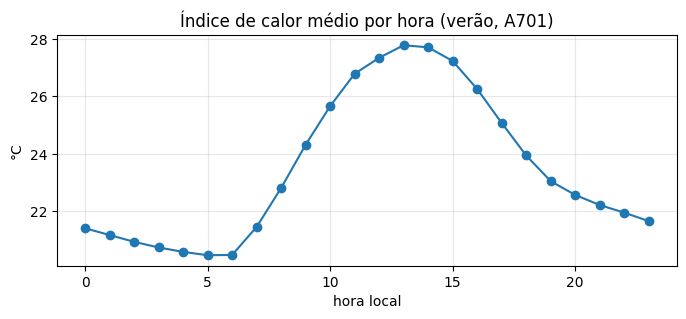

In [3]:
verao = df[df.local.dt.month.isin([12, 1, 2, 3])]
verao.groupby(verao.local.dt.hour)['indice'].mean().plot(marker='o', figsize=(8, 3), title='Índice de calor médio por hora (verão, A701)')
plt.xlabel('hora local'); plt.ylabel('°C'); plt.grid(alpha=.3); plt.show()

## 3. Atributos e alvo
Só atributos que **existem em produção** (o boletim horário do INMET): temperatura, umidade, hora local (em seno e cosseno, para o modelo entender que 23h fica perto de 0h), mês e variação da temperatura na última hora. O alvo é o índice de calor **2 horas depois**. Só entram linhas com as horas vizinhas presentes (sem buracos).

In [4]:
uma_h, duas_h = pd.Timedelta(hours=1), pd.Timedelta(hours=2)
anterior = df['temperatura_c'].reindex(df.index - uma_h).to_numpy()
futuro = df['indice'].reindex(df.index + duas_h).to_numpy()
X = pd.DataFrame({
    'temperatura_c': df.temperatura_c,
    'umidade_pct': df.umidade_pct,
    'hora_sen': np.sin(2 * np.pi * df.local.dt.hour / 24),
    'hora_cos': np.cos(2 * np.pi * df.local.dt.hour / 24),
    'mes_sen': np.sin(2 * np.pi * df.local.dt.month / 12),
    'mes_cos': np.cos(2 * np.pi * df.local.dt.month / 12),
    'variacao_1h': df.temperatura_c.to_numpy() - anterior,
}, index=df.index)
dados = X.assign(indice_agora=df['indice'], alvo=futuro).dropna()
ano = dados.index.year
treino, valid, teste = dados[ano <= 2023], dados[ano == 2024], dados[ano == 2025]
ATRIBUTOS = list(X.columns)
print('treino', len(treino), '| validação', len(valid), '| teste', len(teste))

treino 17194 | validação 8742 | teste 8645


## 4. Modelos
Divisão **por tempo** (sem embaralhar): treina em 2022–2023, escolhe o modelo em 2024 e só no fim mede em 2025. Três candidatos: o baseline "daqui a 2 h = agora", uma regressão linear e uma árvore rasa (fácil de exportar e de explicar).

In [5]:
def avalia(nome, previsto, real):
    reais = [nivel(v) for v in real]
    presentes = [n for n in NIVEIS if n in reais]  # 'perigo' não aparece na A701 em 2022-2025: fica fora da média
    return {'modelo': nome, 'MAE (°C)': round(mean_absolute_error(real, previsto), 3),
            'F1 macro (níveis)': round(f1_score(reais, [nivel(v) for v in previsto], average='macro', labels=presentes, zero_division=0), 3)}

linear = LinearRegression().fit(treino[ATRIBUTOS], treino.alvo)
arvore = DecisionTreeRegressor(max_depth=6, min_samples_leaf=50, random_state=42).fit(treino[ATRIBUTOS], treino.alvo)
candidatos = {'baseline (agora)': lambda d: d.indice_agora.to_numpy(),
              'regressão linear': lambda d: linear.predict(d[ATRIBUTOS]),
              'árvore (prof. 6)': lambda d: arvore.predict(d[ATRIBUTOS])}
validacao = pd.DataFrame([avalia(n, f(valid), valid.alvo) for n, f in candidatos.items()])
validacao

,modelo,MAE (°C),F1 macro (níveis)
0,baseline (agora),1.479,0.652
1,regressão linear,1.098,0.671
2,árvore (prof. 6),1.125,0.637


In [6]:
escolhido = validacao[validacao.modelo != 'baseline (agora)'].sort_values('MAE (°C)').iloc[0].modelo
print('modelo escolhido na validação:', escolhido)
resultado_teste = pd.DataFrame([avalia(n, f(teste), teste.alvo) for n, f in candidatos.items()])
resultado_teste

modelo escolhido na validação: regressão linear


,modelo,MAE (°C),F1 macro (níveis)
0,baseline (agora),1.442,0.667
1,regressão linear,1.052,0.745
2,árvore (prof. 6),1.087,0.689


### Onde o modelo acerta e onde erra (teste, 2025)

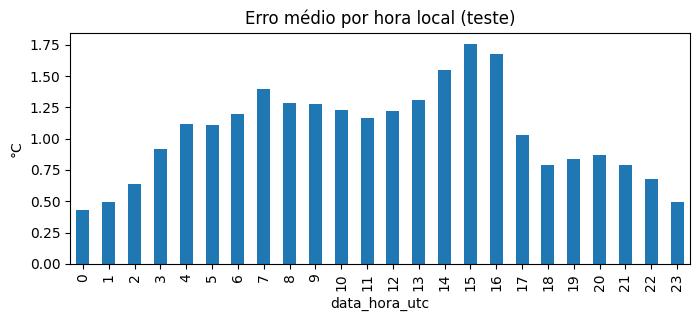

previsto,atencao,cuidado,normal
real,,,
atencao,673,9,218
cuidado,29,19,0
normal,132,3,7562


In [7]:
prev = candidatos[escolhido](teste)
erro = pd.Series(np.abs(prev - teste.alvo.to_numpy()), index=teste.index)
erro.groupby(teste.index.tz_convert('America/Sao_Paulo').hour).mean().plot(kind='bar', figsize=(8, 3), title='Erro médio por hora local (teste)')
plt.ylabel('°C'); plt.show()
pd.crosstab(pd.Series([nivel(v) for v in teste.alvo], name='real'), pd.Series([nivel(v) for v in prev], name='previsto'))

## 5. Exportar `modelo.json`
A API (C#) carrega este arquivo e aplica o modelo: não há servidor Python em produção. O JSON leva os atributos na ordem, os coeficientes (linear) ou os nós da árvore, e as métricas de teste.

In [8]:
def arvore_json(m):
    t = m.tree_
    def no(i):
        if t.children_left[i] == -1:
            return {'valor': round(float(t.value[i][0][0]), 4)}
        return {'atributo': ATRIBUTOS[t.feature[i]], 'limite': round(float(t.threshold[i]), 6),
                'menor_ou_igual': no(t.children_left[i]), 'maior': no(t.children_right[i])}
    return no(0)

metricas = resultado_teste.set_index('modelo').loc[escolhido].to_dict()
base = resultado_teste.set_index('modelo').loc['baseline (agora)'].to_dict()
modelo = {'versao': 1, 'alvo': 'indice_calor_c em 2 h', 'horizonte_horas': 2, 'atributos': ATRIBUTOS,
          'fonte': 'INMET A701, horário, 2022-2025 (treino 2022-2023, validação 2024, teste 2025)',
          'metricas_teste': metricas, 'baseline_teste': base}
if escolhido == 'regressão linear':
    modelo |= {'tipo': 'linear', 'intercepto': round(float(linear.intercept_), 6),
               'coeficientes': {a: round(float(c), 6) for a, c in zip(ATRIBUTOS, linear.coef_)}}
else:
    modelo |= {'tipo': 'arvore', 'raiz': arvore_json(arvore)}
with open('modelo.json', 'w', encoding='utf-8') as f:
    json.dump(modelo, f, ensure_ascii=False, indent=1)
print('modelo.json:', modelo['tipo'], metricas)

modelo.json: linear {'MAE (°C)': 1.052, 'F1 macro (níveis)': 0.745}


Conferência: a mesma previsão feita lendo o JSON (como a API vai fazer) bate com o modelo do scikit-learn.

In [9]:
def prever_json(m, linha):
    if m['tipo'] == 'linear':
        return m['intercepto'] + sum(m['coeficientes'][a] * linha[a] for a in m['atributos'])
    n = m['raiz']
    while 'valor' not in n:
        n = n['menor_ou_igual'] if linha[n['atributo']] <= n['limite'] else n['maior']
    return n['valor']

amostra = teste.sample(200, random_state=1)
diferenca = max(abs(prever_json(modelo, r) - candidatos[escolhido](amostra.loc[[i]])[0]) for i, r in amostra.iterrows())
assert diferenca < 0.01, diferenca
print('diferença máxima JSON x scikit-learn:', round(diferenca, 5))

diferença máxima JSON x scikit-learn:

 1e-05


## 6. Conclusões e limitações
- O modelo é comparado com o baseline "daqui a 2 h = agora", que é o que uma pessoa faria olhando o termômetro. A tabela de teste mostra quanto ele ganha.
- A previsão é da **rua**. A sala entra pela regra do delta (média das últimas 3 h da diferença sala − rua, medida pelo ESP32), que é simples e auditável. Ela supõe que a diferença das últimas 3 h se mantém nas próximas 2 h; no fim da tarde tende a superestimar.
- Os dados são públicos e reais (INMET). As leituras da sala no Wokwi e no modo demonstração são simuladas, e o README diz isso.
- Próximo passo: com uma semana de leituras reais da sala (termo-higrômetro anotado pelo professor), avaliar a previsão completa da sala contra o que a sala realmente teve 2 h depois.